# Modèle global de tarification automobile — version principale

**Version du 9 novembre 2026.**

La prime pure est le produit de la probabilité de sinistre et du montant moyen
conditionnel à un sinistre. Cette version conserve la gravité publiée de `main`
et importe la recette finale de fréquence de `projet-simplifie`.

- **Gravité :** XGBoost Gamma, contrat, prix et ancienneté du véhicule, classe géographique.
- **Fréquence :** 50 % logistique E et 50 % XGBoost recalibré ; 20 modèles XGBoost.
- **Prédiction finale :** `prime_predite = probabilite_sinistre × gravite_predite`.

Les origines exactes sont dans `integration_sources.json`. Les recherches et
versions antérieures sont conservées dans `archive/`.

## 1. Charger et vérifier la version actuelle

Ce notebook charge le modèle sauvegardé et reproduit les prédictions. Il ne
réentraîne pas les composants à chaque lecture. Le checksum est contrôlé avant
la désérialisation.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
cwd=Path.cwd().resolve()
ROOT=next(p for p in [cwd,*cwd.parents] if (p/'integration_sources.json').exists())
sys.path.insert(0,str(ROOT))
import run as app
model=app.load()
manifest=json.loads((ROOT/'models/global_model.json').read_text())
display(pd.Series({'version':manifest['version'],
                   'origine_gravite':manifest['sources']['severity_commit'],
                   'origine_frequence':manifest['sources']['frequency_commit'],
                   'gravite_reentrainee':manifest['severity']['refitted'],
                   'poids_xgboost_frequence':manifest['frequency']['blend_weight']},name='valeur').to_frame())

Matplotlib is building the font cache; this may take a moment.


/home/cytech/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


,valeur
version,global-2026-11-09
origine_gravite,ea9fb85
origine_frequence,682b3c5604b3fdf0ff9425a6c5b86c97df7640a1
gravite_reentrainee,False
poids_xgboost_frequence,0.5


## 2. Validation commune à la fréquence et à la gravité

Le découpage sépare les clients : 39 964 contrats d’apprentissage et 10 036 de
validation, dont respectivement 2 356 et 561 sinistres positifs. Les encodages et
la calibration de fréquence sont appris dans le développement. La gravité
conserve exactement son artefact, ajusté sur les sinistres des mêmes 80 %.

La RMSE de **prime** est mesurée sur tous les contrats de validation, y compris
les non-sinistrés. La RMSE de **gravité** porte uniquement sur leurs montants
positifs. Les scores des anciennes soumissions ne sont pas des scores de ce
nouveau couple. Les données ont déjà été explorées historiquement ; cette
validation ne représente pas une cohorte externe neuve.

In [2]:
metrics=json.loads((ROOT/'reports/validation.json').read_text())
display(pd.Series(metrics,name='valeur').to_frame())
assert metrics['shared_clients']==0
assert metrics['training_contracts']==39964 and metrics['validation_contracts']==10036
assert metrics['validation_positive_claims']==561

,valeur
validation_contracts,10036.000000
validation_positive_claims,561.000000
training_contracts,39964.000000
training_positive_claims,2356.000000
shared_clients,0.000000
premium_rmse_euros,535.213925
premium_mae_euros,188.020429
premium_predicted_observed_ratio,1.031293
constant_premium_rmse_euros,539.119340
frequency_log_loss,0.206002


## 3. Prédire la prime pure et exporter la soumission

Les deux composantes utilisent exactement les mêmes lignes. Le fichier produit
est `outputs/submission.csv`, colonnes `index,pred`. Les composantes et prédictions
par contrat restent locales ; seules les statistiques agrégées sont affichées.

In [3]:
test=app.read(ROOT/'Data/test.csv')
components=app.write_predictions(model,test,ROOT/'outputs/submission.csv',ROOT/'outputs/test_components.csv')
assert len(components)==len(test)==50000
assert components['index'].tolist()==test['index'].tolist()
assert components['probabilite_sinistre'].between(0,1).all()
assert components['gravite_predite'].gt(0).all()
np.testing.assert_allclose(components['prime_predite'],components['probabilite_sinistre']*components['gravite_predite'],rtol=0,atol=0)
display(components.drop(columns='index').describe(percentiles=[.5,.9,.99]).T)

50,000 pure premiums written to /data/cours/Data Science/Project/TD-Tarification-automobile-par-Machine-Learning/outputs/submission.csv


,count,mean,std,min,50%,90%,99%,max
probabilite_sinistre,50000.0,0.058638,0.029590,0.002839,0.059365,0.096034,0.134151,0.265786
gravite_predite,50000.0,1654.255167,252.346283,1045.191895,1719.293823,1954.741821,2040.282227,2206.850586
prime_predite,50000.0,102.700878,59.707606,3.217882,104.967737,177.669560,256.080183,500.119133


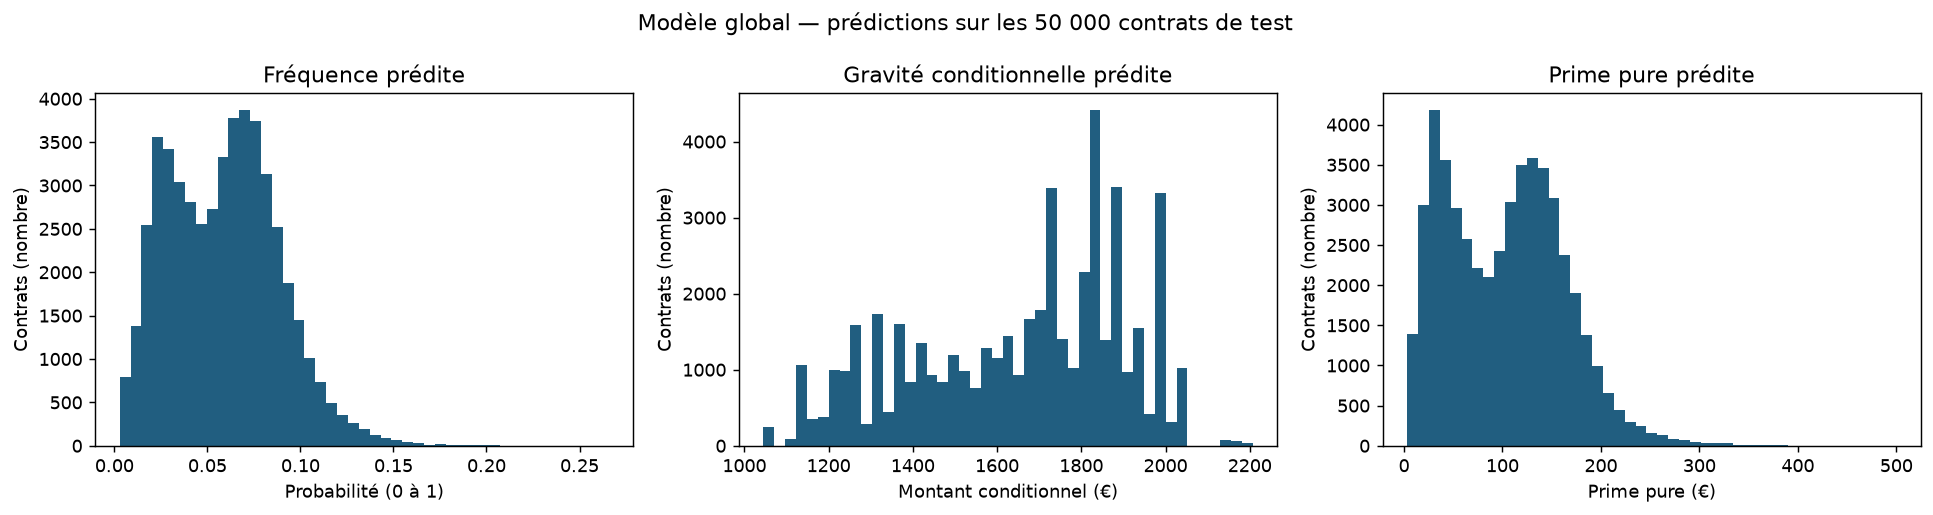

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col,title,unit in zip(axes,
    ['probabilite_sinistre','gravite_predite','prime_predite'],
    ['Fréquence prédite','Gravité conditionnelle prédite','Prime pure prédite'],
    ['Probabilité (0 à 1)','Montant conditionnel (€)','Prime pure (€)']):
    ax.hist(components[col],bins=45,color='#215e80')
    ax.set(title=title,xlabel=unit,ylabel='Contrats (nombre)')
fig.suptitle('Modèle global — prédictions sur les 50 000 contrats de test')
fig.tight_layout()
(ROOT/'reports').mkdir(exist_ok=True)
fig.savefig(ROOT/'reports/01_prediction_distributions.png',dpi=130,bbox_inches='tight')
display(Image(filename=str(ROOT/'reports/01_prediction_distributions.png')))
plt.close(fig)

## 4. Reproduction et anciennes versions

Depuis la racine :

```sh
python run.py train --threads 2
python run.py verify
python run.py predict --input Data/test.csv --output outputs/submission.csv
python -m pytest
```

`train` réapprend la fréquence sur les 80 %, recharge la gravité sans la modifier,
évalue le produit sur les 20 %, contrôle le rechargement et produit la soumission.
Les quatre configurations de fréquence, les cinq graines et le poids 50/50 sont
fixés avant cette évaluation ; aucune optimisation sur les 20 % n’est effectuée.

La fréquence était réentraînée sur tout le portefeuille dans sa branche d’origine.
Ici, son ajustement est limité aux clients d’apprentissage pour partager la
validation de la gravité. Le runtime CPU commun conserve la version XGBoost 3.0.2
de la gravité. Les scores de cette intégration sont donc recalculés et clairement
séparés des anciens scores.

Les anciennes pipelines, analyses et notebooks sont rangés dans `archive/`.
Le présent notebook et `run.py` désignent désormais la version principale.